# Cây quyết định

Cây quyết định là một chuỗi câu hỏi if–else, ví dụ: điểm bài cơ bản dưới 6 thì vào nhóm làm quen, còn lại thì hỏi tiếp điểm bài khác. Khác với code tự viết, cây tự chọn câu hỏi và ngưỡng từ dữ liệu. Bài này học cách cây chọn câu hỏi ở mỗi nút, và cách giới hạn cây để nó không học thuộc dữ liệu train.

> **Mục tiêu**
>
> - Tính Gini và chọn ngưỡng chia tốt nhất ở một nút.
> - Duyệt cây để ra dự đoán.
> - Giới hạn độ sâu và số lá để tránh overfitting.

## Cấu trúc

Mỗi nút trong hỏi một câu dạng $x_j \le t$ (“tuổi $\le 30$?”, “số lần đăng nhập $\le 2$?”). Trả lời có thì đi nhánh trái, không thì đi nhánh phải. Đi từ nút gốc xuống tới nút lá, nơi không còn câu hỏi nào. Mỗi lá chứa một dự đoán: lớp chiếm đa số (phân loại) hoặc giá trị trung bình (hồi quy) của các mẫu train rơi vào lá đó.

Về hình học, cây chia không gian đặc trưng thành các hộp chữ nhật có cạnh song song với trục, mỗi hộp một dự đoán.



**Hỏi nhanh.** Hai lớp được tách đúng bởi đường chéo $x_1 = x_2$. Cây quyết định chỉ dùng phép chia dạng $x_j \le t$ thì biểu diễn ranh giới này thế nào?

- A. Một phép chia $x_1 \le x_2$ ở gốc là đủ
- B. Hai phép chia, mỗi trục một lần, là vừa khít
- C. Không biểu diễn được, dù cây sâu đến đâu
- D. Bằng một bậc thang, cần nhiều phép chia

<details><summary>Đáp án</summary>

D. Bằng một bậc thang, cần nhiều phép chia

Mỗi phép chia chỉ so một feature với một hằng số, nên không có câu hỏi kiểu $x_1 \le x_2$. Cây xấp xỉ đường chéo bằng những bậc thang, càng sát thì càng cần nhiều nút. Tạo thêm feature $x_1 - x_2$ thì một phép chia là đủ.

</details>

## Thế nào là một câu hỏi tốt

Câu hỏi tốt tạo ra các nhóm con thuần (pure): gần như toàn một lớp. Độ “lẫn lộn” của một nút với tỉ lệ các lớp $p_1, \dots, p_K$ được đo bằng

$$\text{Gini} = 1 - \sum_{k=1}^{K} p_k^2, \qquad \text{Entropy} = -\sum_{k=1}^{K} p_k \log_2 p_k.$$

Cả hai bằng 0 khi nút thuần và lớn nhất khi các lớp chia đều. Gini là xác suất đoán sai nếu gán nhãn ngẫu nhiên theo đúng tỉ lệ trong nút; entropy là lượng thông tin, tính bằng bit, cần để biết nhãn. Trong thực tế hai cách cho cây gần như giống nhau; Gini tính nhanh hơn vì không có log.

Ví dụ:

- Nút có 4 mẫu “Đạt”, 2 mẫu “Trượt”: entropy là $-\tfrac46\log_2\tfrac46 - \tfrac26\log_2\tfrac26 \approx 0.92$ bit. (Dùng log tự nhiên thì ra $0.64$, sai đơn vị.)
- Ba lớp với số mẫu 6, 2, 2: Gini $= 1 - 0.6^2 - 0.2^2 - 0.2^2 = 0.56$.



Một phép chia đưa nút cha có $n$ mẫu thành hai con $n_L$ và $n_R$ mẫu. Độ giảm tạp chất (impurity decrease) của phép chia là

$$\Delta = I(\text{cha}) - \frac{n_L}{n} I(\text{trái}) - \frac{n_R}{n} I(\text{phải}).$$

Với entropy, $\Delta$ được gọi là information gain. Với hồi quy, thay $I$ bằng phương sai của $y$ trong nút: chia tốt là chia sao cho mỗi bên có $y$ đồng đều.

**Hỏi nhanh.** Một nút có 3 mẫu lớp 0 và 1 mẫu lớp 1. Gini của nút bằng bao nhiêu?

- A. 0.25
- B. 0.5
- C. 0.375
- D. 0.75

<details><summary>Đáp án</summary>

C. 0.375

$1 - (3/4)^2 - (1/4)^2 = 3/8$. $0.25$ là tỉ lệ của lớp ít hơn. $0.5$ là Gini lớn nhất có thể với hai lớp, khi hai lớp chia đều.

</details>

Giờ dùng Gini để so hai cách chia. Nút cha có 5 mẫu dương và 5 mẫu âm, nên $\text{Gini} = 1 - 0.5^2 - 0.5^2 = 0.5$:

| Cách chia | Trái | Phải | Gini trái | Gini phải | Gini có trọng số | $\Delta$ |
|---|---|---|---|---|---|---|
| A | 4+, 1− | 1+, 4− | 0.32 | 0.32 | 0.32 | **0.18** |
| B | 5+, 3− | 0+, 2− | 0.469 | 0 | 0.375 | 0.125 |

Cách B tạo được một nút hoàn toàn thuần, trông hấp dẫn, nhưng nút đó chỉ có 2 mẫu và nút còn lại vẫn rất lộn xộn. Cách A tốt hơn. Dùng entropy cũng ra cùng kết luận: gain của A là 0.278, của B là 0.236.



## Huấn luyện: tham lam từng bước

Tìm cây tối ưu toàn cục là bài toán NP-khó. Thuật toán CART dùng chiến lược tham lam: ở mỗi nút, thử mọi đặc trưng và mọi ngưỡng, chọn phép chia có $\Delta$ lớn nhất, rồi đệ quy xuống hai con.

Với một đặc trưng, sắp các mẫu theo giá trị rồi chỉ cần thử ngưỡng nằm giữa hai giá trị liên tiếp. Duyệt từ trái sang phải và cập nhật số đếm từng lớp bằng tiền tố, mỗi ngưỡng tính trong $O(1)$. Tổng chi phí cho một nút là $O(d\, n \log n)$, chủ yếu do sắp xếp. Histogram gradient boosting (bài 2.7) gom giá trị vào khoảng 256 thùng để chỉ phải thử vài trăm ngưỡng; `DecisionTreeClassifier` thông thường thì thử mọi ngưỡng giữa các giá trị khác nhau.

**Hỏi nhanh.** Một feature có 1000 mẫu nhưng chỉ có 7 giá trị khác nhau, là các điểm từ 4 đến 10. Ở một nút chứa đủ cả 7 giá trị, CART cần thử bao nhiêu ngưỡng cho feature này?

- A. 999
- B. 1000
- C. 6
- D. 7

<details><summary>Đáp án</summary>

C. 6

Chỉ cần đặt ngưỡng giữa hai giá trị liên tiếp khác nhau, mà 7 giá trị thì có 6 khoảng. Mọi ngưỡng khác nằm trong cùng một khoảng đều chia mẫu y hệt nhau.

</details>

## Khi nào dừng

Khi không có hồ sơ đặc trưng trùng nhau mang nhãn mâu thuẫn và không có ràng buộc dừng, cây có thể mọc tới các lá thuần, lỗi train bằng 0, và cây thuộc lòng cả nhiễu. Các cách hãm:

- `max_depth`: giới hạn độ sâu.
- `min_samples_leaf`: mỗi lá phải có ít nhất bấy nhiêu mẫu. Thường là tham số hiệu quả nhất. Nó chặn luôn số lá: 100 mẫu với `min_samples_leaf=20` thì cây có nhiều nhất 5 lá.
- `min_impurity_decrease`: không chia nếu lợi ích quá nhỏ.
- Cắt tỉa (pruning): mọc cây đầy đủ rồi cắt bớt nhánh. Cost-complexity pruning cực tiểu $\text{lỗi} + \alpha \cdot (\text{số lá})$, cũng là kiểu “lỗi + phạt” quen thuộc ở bài 2.2.

**Hỏi nhanh.** Cost-complexity pruning chọn cây con có $\text{lỗi train} + \alpha\cdot(\text{số lá})$ nhỏ nhất. Tăng $\alpha$ thì cây sau khi tỉa thay đổi thế nào?

- A. Nhiều lá hơn, vì $\alpha$ thưởng cho mỗi lá
- B. Ít lá hơn, và lỗi train không giảm
- C. Không đổi, vì $\alpha$ chỉ ảnh hưởng tới validation
- D. Sâu hơn, nhưng mỗi tầng ít lá hơn

<details><summary>Đáp án</summary>

B. Ít lá hơn, và lỗi train không giảm

Mỗi lá tốn thêm $\alpha$, nên $\alpha$ lớn thì chỉ giữ lại những nhánh giảm lỗi đủ nhiều. Cây nhỏ đi thì lỗi train tăng hoặc giữ nguyên. $\alpha$ cũng là hyperparameter, chọn bằng validation giống $\lambda$ ở bài 2.2.

</details>

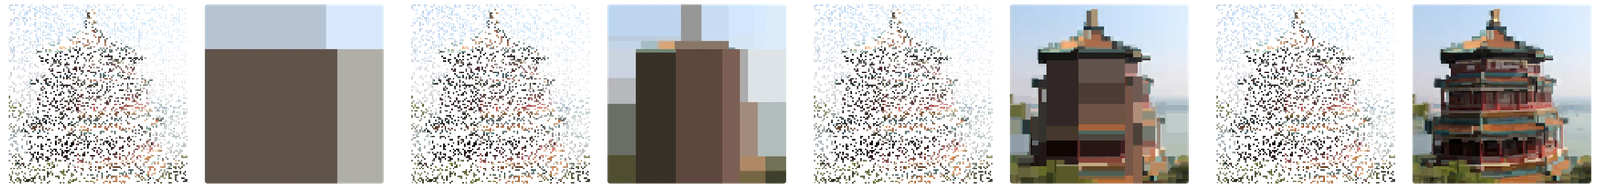

## Điểm mạnh, điểm yếu

**Mạnh**

- Không cần chuẩn hóa đặc trưng: câu hỏi $x_j \le t$ không quan tâm đơn vị đo. Đổi đơn vị hay lấy log một cột chỉ dời ngưỡng, vì thứ tự các giá trị giữ nguyên; cách chia các mẫu không đổi.
- Tự bắt được quan hệ phi tuyến và tương tác giữa các đặc trưng.
- Đọc được như một bộ luật; dễ giải thích cho người không học máy.

**Yếu**

- Variance rất cao: đổi vài mẫu train là cây có thể khác hẳn từ gốc.
- Ranh giới chỉ gồm các đoạn song song với trục; một đường chéo đơn giản phải xấp xỉ bằng hình bậc thang. Biết trước ranh giới là $x_1 = x_2$ thì thêm cột $x_1 - x_2$, một câu hỏi là đủ.
- Dự đoán là hằng số từng khúc, nên **không ngoại suy**: giá trị vượt quá vùng train vẫn chỉ nhận giá trị của lá ngoài cùng.



Chính điểm yếu thứ nhất là lý do người ta ít dùng một cây đơn lẻ, mà gộp nhiều cây lại ở bài 2.6 và 2.7.

**Hỏi nhanh.** Bỏ ngẫu nhiên 5 trong 500 mẫu train rồi học lại. Cây sâu đổi hẳn phép chia ở gốc, và dự đoán trên validation thay đổi nhiều. Điều này cho thấy gì?

- A. 5 mẫu bị bỏ đi là những mẫu bị gán nhãn sai
- B. Variance cao: dữ liệu đổi ít mà cây đổi nhiều
- C. Cây có bias cao, cần mọc sâu hơn nữa
- D. Phải chuẩn hóa feature trước khi học cây

<details><summary>Đáp án</summary>

B. Variance cao: dữ liệu đổi ít mà cây đổi nhiều

Cây chọn phép chia theo kiểu tham lam, nên một thay đổi nhỏ ở gốc lan xuống cả cây. Đó là variance. Lấy trung bình nhiều cây học trên các mẫu khác nhau sẽ giảm đúng phần này (bài 2.6). Cây không cần chuẩn hóa.

</details>

## Độ quan trọng đặc trưng

Muốn biết đặc trưng nào quan trọng, có hai cách:

- **Impurity importance**: cộng dồn $\Delta$ (có trọng số theo số mẫu) của mọi phép chia dùng đặc trưng $j$. Cách này nhanh nhưng thiên vị các đặc trưng có nhiều giá trị khác nhau, như ID hay số thực. Cực đoan nhất là cột mã học sinh, mỗi mẫu một giá trị: chia theo nó cho toàn lá thuần, information gain tối đa mà chẳng học được gì. (Thuật toán C4.5 chia gain cho entropy của chính phép chia, gọi là gain ratio, để hãm chuyện này.)
- **Permutation importance**: xáo trộn cột $j$ trên tập validation rồi đo điểm giảm bao nhiêu. Cách này đáng tin hơn.

**Hỏi nhanh.** Lỡ để cột `row_id` trong feature, mỗi dòng một số khác nhau. Cây sâu cho cột này impurity importance cao, nhưng permutation importance trên validation thì gần bằng 0. Hiểu thế nào?

- A. `row_id` thật sự quan trọng, phải giữ lại
- B. Permutation importance tính sai, nên tin impurity importance
- C. Hai cách đo luôn cho kết quả trái ngược nhau
- D. Cây dùng `row_id` để học thuộc train

<details><summary>Đáp án</summary>

D. Cây dùng `row_id` để học thuộc train

Cột có nhiều giá trị khác nhau cho vô số ngưỡng để tách riêng từng mẫu, nên gom được nhiều mức giảm impurity trên train. Trên validation, `row_id` không mang thông tin gì, nên xáo trộn nó cũng không làm điểm giảm. Bỏ cột này đi rồi kiểm lại.

</details>

## Cài một nút trước khi cài cả cây

Ta bắt đầu nhỏ hơn CART đầy đủ: chỉ một đặc trưng, một phép chia, gọi là decision stump. Bốn điểm có tọa độ 1, 2, 3, 4 và nhãn 0, 0, 1, 1. Nút gốc có hai lớp ngang nhau nên Gini bằng $1-(1/2)^2-(1/2)^2=0.5$. Chia ở 2.5 tạo hai lá thuần, Gini sau chia bằng 0; mức giảm là 0.5.

Điểm đáng chú ý là Gini sau chia phải lấy **trung bình có trọng số số mẫu**. Một lá có 1 mẫu và một lá có 99 mẫu không thể có tiếng nói ngang nhau. Ta chỉ xét ngưỡng giữa hai giá trị liên tiếp khác nhau: trong khoảng đó không điểm nào đổi bên nên xét thêm cũng vô ích.

In [ ]:
import numpy as np

def gini(labels):
    counts = np.bincount(labels, minlength=2)
    probabilities = counts / len(labels)
    return 1.0 - np.sum(probabilities ** 2)

x_small = np.array([1., 2., 3., 4.])
y_small = np.array([0, 0, 1, 1])
best = None
for threshold in [1.5, 2.5, 3.5]:
    left = x_small <= threshold
    right = ~left
    after = left.mean() * gini(y_small[left]) + right.mean() * gini(y_small[right])
    gain = gini(y_small) - after
    print(threshold, round(float(gain), 3))
    if best is None or gain > best[0]:
        best = (gain, threshold)
print("ngưỡng:", best[1])
assert best[1] == 2.5

1.5 0.167
2.5 0.5
3.5 0.167
ngưỡng: 2.5


Đọc cột gain: ngưỡng 2.5 thắng hai ngưỡng còn lại, dù cả ba đều chia được dữ liệu thành hai phần. Cài cả cây là lặp lại việc này cho từng nút bằng đệ quy, dừng khi lá đủ thuần, quá ít mẫu hoặc đạt độ sâu. Khi nhiều phép chia hòa gain, cần quy tắc phá hòa. Bản nhỏ trên giữ ngưỡng gặp trước; thư viện có quy tắc và ngẫu nhiên riêng nên không được đòi mọi cây giống hệt nhau.





**Hỏi nhanh.** Sau một phép chia, lá trái có 2 mẫu với Gini bằng 0, lá phải có 18 mẫu với Gini bằng 0.5. Gini có trọng số sau khi chia bằng bao nhiêu?

- A. 0.25
- B. 0.45
- C. 0.5
- D. 0.9

<details><summary>Đáp án</summary>

B. 0.45

$(2/20)\cdot 0 + (18/20)\cdot 0.5 = 0.45$. Lấy trung bình đều của hai lá thì ra $0.25$, coi lá nhỏ quan trọng quá mức.

</details>

## Vì sao tham lam có giới hạn

Decision tree tìm phép chia tốt nhất **ngay ở nút hiện tại**, không thử mọi cây tương lai. Một ví dụ là XOR: hai bit đầu vào 00, 01, 10, 11 có nhãn 0, 1, 1, 0. Chia theo bit nào ở gốc cũng có gain 0, nhưng chia thêm ở tầng sau thì phân loại được hết. Nếu đặt điều kiện chỉ chia khi gain dương rõ rệt, cây có thể bỏ lỡ tương tác này. Câu “cây tự học mọi tương tác” vì vậy cần hiểu là khả năng biểu diễn, chưa bảo đảm thuật toán tham lam sẽ tìm ra.



**Hỏi nhanh.** Bốn điểm XOR: $(0,0) \to 0$, $(0,1) \to 1$, $(1,0) \to 1$, $(1,1) \to 0$. Ở gốc, chia theo $x_1$ thì Gini giảm được bao nhiêu?

- A. 0
- B. 0.25
- C. 0.5
- D. 1

<details><summary>Đáp án</summary>

A. 0

Gốc có Gini $0.5$. Sau khi chia theo $x_1$, mỗi lá vẫn có một mẫu lớp 0 và một mẫu lớp 1, Gini vẫn là $0.5$. Trung bình có trọng số bằng $0.5$, nên mức giảm là 0. Chia theo $x_2$ cũng vậy. Phải sang tầng sau thì mỗi phép chia mới tách hết được.

</details>

Đối với hồi quy, một lá dự đoán trung bình nhãn các mẫu train rơi vào lá đó. Dự đoán luôn ở trong khoảng các nhãn lá, nên đưa $x$ ra xa vùng train cũng chỉ nhận cùng một giá trị ở lá ngoài cùng. Đây là lý do cây không kéo dài xu hướng như linear regression. Nếu bài có giá trị tương lai vượt xa lịch sử, hãy kiểm ngoại suy trên validation có cấu trúc tương tự, thay vì chỉ random split.



## Dùng thư viện

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier, export_text

X, y = load_breast_cancer(return_X_y=True)
for depth in [1, 3, 5, None]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=0)
    print(depth, round(cross_val_score(tree, X, y, cv=5).mean(), 3))

tree = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X, y)
print(export_text(tree, feature_names=list(load_breast_cancer().feature_names)))

1 0.9
3 0.917
5 0.916
None 0.917
|--- worst radius <= 16.80
|   |--- worst concave points <= 0.14
|   |   |--- class: 1
|   |--- worst concave points >  0.14
|   |   |--- class: 0
|--- worst radius >  16.80
|   |--- worst texture <= 19.91
|   |   |--- class: 1
|   |--- worst texture >  19.91
|   |   |--- class: 0


Đọc cột CV: sâu 3 đạt 0.917, không giới hạn độ sâu cũng 0.917. Cây sâu 3 nông hơn, đọc được thành một bộ luật ngắn, nên là lựa chọn tự nhiên khi điểm ngang nhau.



**Hỏi nhanh.** Cross-validation cho độ sâu 1, 3, 5 và không giới hạn lần lượt được 0.900, 0.917, 0.916 và 0.917. Ta nên chọn gì, vì sao?

- A. Độ sâu 3, vì ngang điểm cao nhất mà đơn giản hơn
- B. Không giới hạn, vì điểm cao nhất và khỏi phải chọn
- C. Độ sâu 1, vì đơn giản nhất và chỉ kém 1.7 điểm
- D. Độ sâu 5, vì nằm giữa nên an toàn nhất

<details><summary>Đáp án</summary>

A. Độ sâu 3, vì ngang điểm cao nhất mà đơn giản hơn

Chênh lệch 0.001 giữa ba cấu hình nhỏ hơn nhiều so với mức dao động giữa các fold. Khi điểm ngang nhau, cây nông dễ đọc, chạy nhanh và ít nhạy với nhiễu hơn. Độ sâu 1 thì thua rõ, hơn một điểm phần trăm.

</details>

## Khi đi thi

- Huấn luyện một cây nông, độ sâu 2–4, để xem cột nào quan trọng. Cây độ sâu 1 mà đạt 99% thì nghi có cột lộ đáp án.
- Đề yêu cầu tự cài cây thì đọc kỹ quy ước: `<=` hay `<`, phá hòa giữa các ngưỡng.
- Test nằm ở tương lai thì nhớ cây không ngoại suy.

## Tóm tắt

- Cây hỏi liên tiếp các câu $x_j \le t$, chia không gian thành hộp, mỗi hộp một dự đoán.
- Chọn phép chia làm giảm tạp chất (Gini, entropy, phương sai) nhiều nhất; huấn luyện tham lam theo CART.
- Cây sâu thì overfit; hãm bằng độ sâu, số mẫu ở lá, hoặc cắt tỉa.
- Không cần chuẩn hóa, bắt được phi tuyến, nhưng variance cao và không ngoại suy.

## Kiểm tra cuối bài

Mười câu kiểm cả cách hiểu, phép tính và quy trình. Câu sai chỉ ra phần cần đọc lại; hãy làm trước khi mở lời giải.

**Câu 1.** Một nút có 10 mẫu thuộc ba lớp, lần lượt 5, 3 và 2 mẫu. Gini impurity bằng bao nhiêu?

- A. 0.38
- B. 0.62
- C. 0.50
- D. 0.67

<details><summary>Đáp án</summary>

B. 0.62

$1 - 0.5^2 - 0.3^2 - 0.2^2 = 1 - 0.38 = 0.62$. $0.38$ là tổng các bình phương, quên lấy 1 trừ đi. $0.67$ là Gini lớn nhất với ba lớp, khi ba lớp chia đều.

</details>
**Câu 2.** Trên cùng tập train $D$, ta học hai cây. Một cây chọn phép chia theo information gain, cây kia theo tỉ lệ lỗi trên train. Cả hai đều mọc cho tới khi lỗi train bằng 0. Điều nào **chắc chắn** đúng?

- A. Hai cây chia theo cùng một feature ở gốc
- B. Hai cây có cùng độ sâu và cùng số lá
- C. Hai cây dùng hết mọi feature của $D$
- D. Hai cây dự đoán giống nhau trên mọi mẫu của $D$

<details><summary>Đáp án</summary>

D. Hai cây dự đoán giống nhau trên mọi mẫu của $D$

Lỗi train bằng 0 nghĩa là cả hai cây đều trả đúng nhãn cho mọi mẫu train, nên dự đoán trên $D$ trùng nhau. Tiêu chí chia khác nhau có thể chọn gốc khác, độ sâu khác, và bỏ qua những feature khác nhau. Trên dữ liệu mới, hai cây cũng có thể cho kết quả khác nhau.
Phỏng theo: [CMU 10-601 · Exam 1 Practice · Q1.2](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam1_practice_problems.pdf#page=6)

</details>
**Câu 3.** Một lá của cây hồi quy có target là 2, 4 và 9. Hằng số dự đoán nào làm MSE trên lá này nhỏ nhất?

- A. 4
- B. 9
- C. 5
- D. 15

<details><summary>Đáp án</summary>

C. 5

Trung bình $(2 + 4 + 9)/3 = 5$ làm tổng bình phương sai số nhỏ nhất. Còn 4 là median, làm MAE nhỏ nhất.

</details>
**Câu 4.** Thuật toán học cây kiểu ID3 hay CART có bảo đảm tìm ra cây đạt lỗi train 0 với **ít phép chia nhất** không?

- A. Có, vì ở mỗi nút đều thử mọi feature và mọi ngưỡng
- B. Có, nếu dùng entropy thay cho Gini
- C. Không, vì nó chỉ chọn phép chia tốt nhất tại từng nút
- D. Không, vì cây không bao giờ đạt được lỗi train 0

<details><summary>Đáp án</summary>

C. Không, vì nó chỉ chọn phép chia tốt nhất tại từng nút

Thử mọi phép chia **tại một nút** khác với thử mọi cây có thể có. Ví dụ XOR cho thấy phép chia tốt nhất trước mắt chưa chắc dẫn tới cây gọn nhất. Tìm cây tối ưu toàn cục là bài toán NP-khó. Còn cây không bị giới hạn thì thường đạt lỗi train 0, trừ khi có hai mẫu giống hệt nhau mà khác nhãn.
Phỏng theo: [CMU 10-601 · Exam 1 Practice · Q1.3](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam1_practice_problems.pdf#page=6)

</details>
**Câu 5.** Dữ liệu dự đoán khách bỏ dịch vụ có 10 000 mẫu và 20 feature. Có 15% số ô bị thiếu, rải ngẫu nhiên. Trong bốn đề xuất sau, lập luận nào chính xác nhất?

- A. Dùng mô hình dạng cây, vì nhiều thư viện cây tự học hướng đi cho ô thiếu
- B. kNN cần đủ mọi ô, nên bỏ hết mẫu bị thiếu là cách duy nhất
- C. Linear regression với ô thiếu điền bằng trung bình là cách tối ưu về thống kê
- D. Dùng một mô hình tuyến tính, sau khi điền ô thiếu bằng giá trị của dòng phía trên

<details><summary>Đáp án</summary>

A. Dùng mô hình dạng cây, vì nhiều thư viện cây tự học hướng đi cho ô thiếu

Nhiều thư viện cây hiện đại học xem tại mỗi phép chia nên đưa ô thiếu sang nhánh nào. Cây quyết định của scikit-learn làm được việc này từ bản 1.3. Bỏ mẫu bị thiếu thì chỉ còn khoảng $0.85^{20}\approx 4\%$ số mẫu có đủ 20 ô. Điền bằng trung bình chỉ là một baseline, không phải cách tối ưu. Điền theo dòng phía trên chỉ có nghĩa khi các dòng là một chuỗi thời gian.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 270](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=97)

</details>
**Câu 6.** Cây đúng 100% trên train, 68% trên validation, và cách chia dữ liệu đã được kiểm. Thí nghiệm nào kiểm trực tiếp giả thuyết “cây quá linh hoạt”?

- A. Giảm `max_depth` hoặc tăng `min_samples_leaf`, giữ nguyên các fold
- B. Giảm `min_samples_leaf` để mỗi lá khớp train hơn
- C. Chia lại ngẫu nhiên, lấy lần có accuracy validation cao nhất
- D. Tăng `max_depth` để accuracy trên train tăng tiếp

<details><summary>Đáp án</summary>

A. Giảm `max_depth` hoặc tăng `min_samples_leaf`, giữ nguyên các fold

Giảm độ sâu hay tăng số mẫu tối thiểu ở lá đều hạn chế độ phức tạp của cây. Giữ nguyên các fold thì mới so đúng tác động của thay đổi. Có cải thiện hay không thì phải đo mới biết.
Phỏng theo: [CMU 10-601 · Exam 1 Practice · Q3.1](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam1_practice_problems.pdf#page=14)

</details>
**Câu 7.** Một nút hồi quy có target $(1, 2, 9, 10)$, được chia thành $\{1, 2\}$ và $\{9, 10\}$. Phương sai giảm được bao nhiêu, tính theo trung bình có trọng số?

- A. 16.0
- B. 16.25
- C. 8.0
- D. 0.25

<details><summary>Đáp án</summary>

A. 16.0

Nút cha có trung bình $5.5$, phương sai $(4.5^2 + 3.5^2 + 3.5^2 + 4.5^2)/4 = 16.25$. Mỗi nút con có phương sai $0.25$, nên trung bình có trọng số là $0.25$. Mức giảm là $16.25 - 0.25 = 16.0$. Ra $16.25$ là lấy phương sai của cha mà quên trừ phần còn lại.

</details>
**Câu 8.** Một cây chỉ sâu 1, tức chỉ có một phép chia, mà đúng 99% trên validation của một đề tưởng là khó. Ta nên nghĩ đến điều gì trước tiên?

- A. Đề dễ hơn dự kiến, nộp luôn cây này
- B. Có thể một cột đang lộ đáp án, cần kiểm cột ở gốc
- C. Tăng độ sâu để lên 100%
- D. Cây sâu 1 luôn underfit, nên con số này chỉ là nhiễu

<details><summary>Đáp án</summary>

B. Có thể một cột đang lộ đáp án, cần kiểm cột ở gốc

Một câu hỏi duy nhất mà gần như đúng hết thường là dấu hiệu rò rỉ: cột ấy được tạo ra sau sự kiện, hoặc mã hóa thẳng nhãn. Hãy đọc feature và ngưỡng ở gốc, rồi hỏi xem lúc dự đoán thật cột ấy đã có chưa (bài 1.4).

</details>
**Câu 9.** Cây hồi quy thông thường dự đoán trung bình ở mỗi lá, và `y_train` nằm trong khoảng $[1, 10]$. Với một $x$ nằm ngoài vùng train, điều gì đúng?

- A. Dự đoán vẫn nằm trong $[1, 10]$, vì là trung bình của một lá
- B. Dự đoán tăng tuyến tính theo khoảng cách tới vùng train
- C. Dự đoán có thể bằng 30 nếu cây đủ sâu
- D. Dự đoán phải bằng 10, vì $x$ nằm ngoài vùng train

<details><summary>Đáp án</summary>

A. Dự đoán vẫn nằm trong $[1, 10]$, vì là trung bình của một lá

Cây vẫn đưa $x$ vào một lá có sẵn, và trung bình target trong lá luôn nằm giữa giá trị nhỏ nhất và lớn nhất của train. Chưa biết $x$ nằm lệch về phía nào thì cũng chưa biết nó rơi vào lá nào.

</details>
**Câu 10.** Feature importance cao có chứng minh được cột ấy gây ra target không?

- A. Có, vì mô hình dựa vào cột ấy nhiều nhất
- B. Chỉ khi cây đủ sâu để thấy hết các tương tác
- C. Có, nếu accuracy trên validation gần bằng 1
- D. Không, nó chỉ cho biết mô hình dựa vào cột nào

<details><summary>Đáp án</summary>

D. Không, nó chỉ cho biết mô hình dựa vào cột nào

Importance mô tả mô hình dựa vào cột nào trên dữ liệu này. Nó không nói được chuyện gì xảy ra khi ta can thiệp vào cột ấy. Hai cột tương quan với nhau còn có thể chia importance cho nhau một cách tùy ý.

</details>
## Đọc thêm

- James, Witten, Hastie, Tibshirani — [*An Introduction to Statistical Learning*](https://www.statlearning.com/), chương 8. Cây, cắt tỉa và cầu nối sang bagging, random forest, boosting.
- Géron — *Hands-On Machine Learning*, chương 6. Thực hành decision tree với scikit-learn, kèm phần về độ bất ổn của cây.
- [scikit-learn — Decision Trees](https://scikit-learn.org/stable/modules/tree.html). Đọc thuật toán CART, criterion, giới hạn độ sâu và ví dụ diễn giải cây.
- [ISLP — Tree-based methods lab](https://intro-stat-learning.github.io/ISLP/labs/Ch08-baggboost-lab.html). Thực hành cây, pruning và đối chiếu với ensemble.

Nguồn ảnh: ảnh tháp là ảnh mẫu `china.jpg` kèm scikit-learn (danielbuechele, Flickr, CC BY 2.0).